<a href="https://colab.research.google.com/github/yashas-singhal/devsoc_ai_ml_dev_assignment_2026ACPS0639G/blob/main/2026ACPS0639G.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression

In [2]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe



Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv')

Let's see what the first 5 rows of this dataset looks like

In [4]:
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice
0,11553,1051,1159,336,0,5,AllPub,158000
1,8400,1052,1052,288,0,5,AllPub,138500
2,8960,1008,1028,360,0,6,AllPub,115000
3,11100,0,930,308,0,7,AllPub,84900
4,15593,1304,2287,667,0,4,AllPub,225000


In [5]:
print(df.shape)

# Dataset Exploration

# The training dataset contains 1,314 observations. Each observation represents a house and contains several features used to predict its selling price (SalePrice).

# The numerical features have different ranges and mean values, as shown in the summary table above. Some features are categorical, such as Utilities.

# Since the numerical features have different scales, feature scaling is required to make gradient descent more stable and efficient.

(1314, 8)


What are all the features present? What is the range for each of the features along with their mean?

In [6]:

print(df.columns.tolist())

print(df.describe().T)

print(df.select_dtypes(include=['object', 'category']).columns.tolist())

['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond', 'Utilities', 'SalePrice']
              count           mean           std      min        25%  \
LotArea      1314.0   10622.104262  10430.181058   1300.0    7588.50   
TotalBsmtSF  1314.0    1058.311263    435.717809      0.0     796.00   
GrLivArea    1314.0    1512.900304    524.854432    334.0    1124.25   
GarageArea   1314.0     473.480213    213.960987      0.0     336.00   
PoolArea     1314.0       2.643075     39.504255      0.0       0.00   
OverallCond  1314.0       5.582192      1.112699      1.0       5.00   
SalePrice    1314.0  180795.504566  77511.272784  34900.0  130000.00   

                  50%        75%       max  
LotArea        9501.5   11613.50  215245.0  
TotalBsmtSF     992.0    1295.25    6110.0  
GrLivArea      1461.5    1775.75    5642.0  
GarageArea      480.0     576.00    1418.0  
PoolArea          0.0       0.00     738.0  
OverallCond       5.0       6.00       9.0  
S

In [7]:
numeric_df = df.select_dtypes(include='number')

feature_summary = pd.DataFrame({
    'Min': numeric_df.min(),
    'Max': numeric_df.max(),
    'Range': numeric_df.max() - numeric_df.min(),
    'Mean': numeric_df.mean()
})

print(feature_summary)

               Min     Max   Range           Mean
LotArea       1300  215245  213945   10622.104262
TotalBsmtSF      0    6110    6110    1058.311263
GrLivArea      334    5642    5308    1512.900304
GarageArea       0    1418    1418     473.480213
PoolArea         0     738     738       2.643075
OverallCond      1       9       8       5.582192
SalePrice    34900  755000  720100  180795.504566


### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.
  
These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`
  
These features are called categorical features. We can represent these features as a `One-Hot Representation`
  
  
You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [8]:
# Do the one-hot encoding here

df = pd.get_dummies(df, dtype=int)

print(df.head())
print(df.shape)

   LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0    11553         1051       1159         336         0            5   
1     8400         1052       1052         288         0            5   
2     8960         1008       1028         360         0            6   
3    11100            0        930         308         0            7   
4    15593         1304       2287         667         0            4   

   SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0     158000                 1                 0  
1     138500                 1                 0  
2     115000                 1                 0  
3      84900                 1                 0  
4     225000                 1                 0  
(1314, 9)


In [9]:
# Do the feature scaling here

train_min = df.min()
train_max = df.max()

train_range = train_max - train_min

train_range = train_range.replace(0, 1)

df = (df - train_min) / train_range

print(df.head())

    LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0  0.047924     0.172013   0.155426    0.236953       0.0        0.500   
1  0.033186     0.172177   0.135268    0.203103       0.0        0.500   
2  0.035804     0.164975   0.130746    0.253879       0.0        0.625   
3  0.045806     0.000000   0.112283    0.217207       0.0        0.750   
4  0.066807     0.213421   0.367935    0.470381       0.0        0.375   

   SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0   0.170948               1.0               0.0  
1   0.143869               1.0               0.0  
2   0.111235               1.0               0.0  
3   0.069435               1.0               0.0  
4   0.263991               1.0               0.0  


In [ ]:
# One-Hot Encoding and Feature Scaling

# One-hot encoding is used to convert categorical features into numerical representations so that they can be processed by the Linear Regression model.

# Min-max normalization is applied to scale the numerical features to the range [0, 1], using:

# [
# x(normalized) = [x - x(min)]/[x(max) - x(min)]
# ]

# This ensures that features with large numerical values do not dominate the optimization process merely because of their scale.

# The minimum and maximum values from the training dataset are stored so that the same normalization can be applied to the testing dataset.

### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model
  
Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $

*   List item
*   List item

(X, Y)$. These represent the features and targets respectively

In [10]:
# Convert to numpy array

X_df = df.drop('SalePrice', axis=1)
y_df = df['SalePrice']

feature_columns = X_df.columns.tolist()

x = X_df.to_numpy(dtype=float)
y = y_df.to_numpy(dtype=float).reshape(-1, 1)

print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (1314, 8)
y shape: (1314, 1)


In [11]:
print("Any NaNs in X?", np.isnan(x).any())
print("Any NaNs in y?", np.isnan(y).any())

Any NaNs in X? False
Any NaNs in y? False


## Linear Regression formulation
  
We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction


Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$
  
  
Now how do we extend this to multiple datapoints?  
  
  
Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)

In [12]:
N, D = x.shape

print("Number of training examples:", N)
print("Number of features:", D)
print("Number of parameters:", D + 1)

np.random.seed(42)
w = np.random.randn(1, D)

b = 0.0

y_pred = x @ w.T + b

print("Prediction shape:", y_pred.shape)

Number of training examples: 1314
Number of features: 8
Number of parameters: 9
Prediction shape: (1314, 1)


In [ ]:
# Linear Regression Formulation

# After preprocessing, our training dataset contains 1,314 samples and 8 input features.

# A Linear Regression model learns one weight for each input feature and one additional bias term.

# Therefore, the total number of trainable parameters is:

# D+1=8+1=9

# For a single observation, the model is:

# y=w_1x_1+w_2x_2+\cdots+w_8x_8+b

# For all training samples, this can be expressed using matrix multiplication:

# Y=XW+b

# Here, (X) has shape ((1314,8)), (W) has shape ((8,1)), and the prediction vector has shape ((1314,1)).

# In NumPy, this is implemented as:

# y_pred = x @ w.T + b

# The weights are initially sampled from a standard normal distribution, while the bias is initialized to zero.

How well does our model perform? Try comparing our predictions with the actual values

In [13]:
print("Predicted values:")
print(y_pred[:5])

print("Actual values:")
print(y[:5])

Predicted values:
[[1.92372004]
 [1.85176554]
 [1.89919871]
 [1.82990056]
 [2.44979837]]
Actual values:
[[0.17094848]
 [0.14386891]
 [0.11123455]
 [0.0694348 ]
 [0.26399111]]


In [ ]:
# Initial Predictions

# The initial predictions differ significantly from the actual values because the model's weights are randomly initialized and have not yet been optimized.

# At this stage, the model has not learned the relationship between the input features and house prices.

# We therefore need to train the model using gradient descent to minimize prediction errors.

### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

In [14]:
def mse_loss_fn(y_true, y_pred):
  return np.mean((y_true - y_pred) ** 2)


In [ ]:
# Mean Squared Error measures the average squared difference between the predicted and actual target values.

# The main assumptions associated with classical Linear Regression are:

# The expected target value is a linear function of the input features.

# The errors have zero conditional mean.

# Observations or errors are independent, as appropriate to the dataset.

# Constant error variance and normally distributed errors are commonly assumed for classical statistical inference.

# MSE penalizes larger errors more heavily because the errors are squared. It is also differentiable, making it suitable for optimization using gradient descent.

# Normality and constant variance are not required merely to compute or minimize MSE.

Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

In [15]:
def get_gradients(y_true, y_pred, W, b, X):
    """
    Calculates the gradients for the MSE loss function with respect to the weights (and bias)

    Args:
        y_true: The true values of the target variable (SalePrice in our case)
        y_pred: The predicted values of the target variable using our model (W*X + b)

        W: The weights of the model
        b: The bias of the model
        X: The input features

    Returns:
        dW: The gradients of the loss function with respect to the weights
        db: The gradients of the loss function with respect to the bias
    """
    N = X.shape[0]

    error = y_pred - y_true

    dW = (2 / N) * (X.T @ error)
    db = (2 / N) * np.sum(error)

    return dW.T, db

Update the weights using the gradients

In [16]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    """
    Updates the weights (and bias) using the gradients and the learning rate

    Args:
        weights: The current weights of the model
        bias: The current bias of the model

        gradients_weights: The gradients of the loss function with respect to the weights
        gradients_bias: The gradients of the loss function with respect to the bias

        lr: The learning rate

    Returns:
        weights_new: The updated weights of the model

    """
    weights_new = weights - lr * gradients_weights
    bias_new = bias - lr * gradients_bias

    return weights_new, bias_new

Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs
  
> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code

In [17]:
NUM_EPOCHS = 3000
LEARNING_RATE = 2e-2

losses = []

for epoch in range(NUM_EPOCHS):
    y_pred = x @ w.T + b

    loss = mse_loss_fn(y, y_pred)
    losses.append(loss)

    dw, db = get_gradients(y, y_pred, w, b, x)

    w, b = update(w, b, dw, db, LEARNING_RATE)

print("Initial loss:", losses[0])
print("Final loss:", losses[-1])


Initial loss: 3.6212094760077025
Final loss: 0.005579924400811101


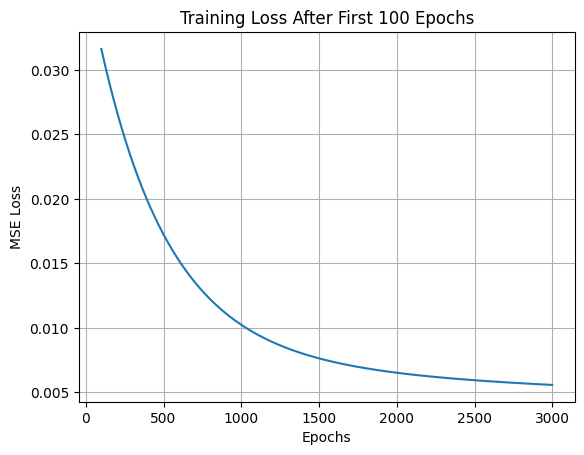

In [18]:
plt.plot(range(100, NUM_EPOCHS), losses[100:])
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training Loss After First 100 Epochs")
plt.grid(True)
plt.show()

Now use matplotlib to plot the loss graph

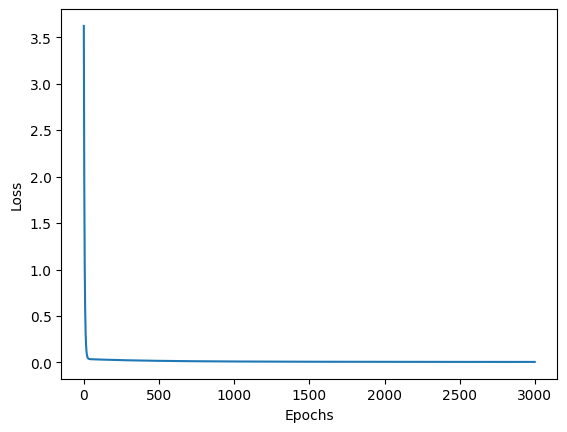

In [19]:
plt.plot(losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### **Testing with test data**

Load and apply all the preprocessing steps used in the training data for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

To load test data from GitHub, use the code below.


In [20]:
df_test_raw = pd.read_csv(
    'https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv'
)

df_test = pd.get_dummies(df_test_raw, dtype=int)

y_test_original = df_test_raw['SalePrice'].to_numpy().reshape(-1, 1)

X_test_df = df_test.drop('SalePrice', axis=1)

X_test_df = X_test_df.reindex(
    columns=feature_columns,
    fill_value=0
)

print("Test data shape:", X_test_df.shape)



Test data shape: (146, 8)


Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

In [21]:
X_test_df = X_test_df.fillna(train_min[feature_columns])

X_test_scaled = (
    X_test_df - train_min[feature_columns]
) / train_range[feature_columns]

x_test = X_test_scaled.to_numpy(dtype=float)

y_test = (
    y_test_original - train_min['SalePrice']
) / train_range['SalePrice']

print("Training shape:", x.shape)
print("Testing shape:", x_test.shape)

print("NaNs in test features:", np.isnan(x_test).any())

Training shape: (1314, 8)
Testing shape: (146, 8)
NaNs in test features: False


In [22]:
print("Number of training features:", x.shape[1])
print("Number of testing features:", x_test.shape[1])

print(
    "Columns aligned correctly:",
    list(X_test_df.columns) == feature_columns
)

print("NaN values in x_test:", np.isnan(x_test).any())

assert x.shape[1] == x_test.shape[1]
assert list(X_test_df.columns) == feature_columns
assert np.isfinite(x_test).all()

print("Test data is ready!")

Number of training features: 8
Number of testing features: 8
Columns aligned correctly: True
NaN values in x_test: False
Test data is ready!


In [23]:
# Make predictions using trained weights and bias
y_pred_test = x_test @ w.T + b

# Calculate MSE for testing data
loss_test = mse_loss_fn(y_test, y_pred_test)

# Calculate MSE for training data
y_pred_train = x @ w.T + b
loss_train = mse_loss_fn(y, y_pred_train)

# Convert predicted prices back to original scale
y_pred_test_scaled = (
    y_pred_test * train_range['SalePrice']
    + train_min['SalePrice']
)

# Store actual house prices in original scale
y_test_scaled = y_test_original

# Display results
print("Training MSE:", loss_train)
print("Testing MSE:", loss_test)

print("Test/Train MSE ratio:", loss_test / loss_train)

Training MSE: 0.005579321141149667
Testing MSE: 0.009931057473048567
Test/Train MSE ratio: 1.7799759543868428


In [24]:
idx = np.random.randint(0, x_test.shape[0], 5)

y_pred_test_sample = y_pred_test_scaled[idx].round().astype(int)
y_true_test_sample = y_test_scaled[idx].round().astype(int)

print('Predicted SalePrice: \t', y_pred_test_sample.squeeze().tolist())
print('Actual SalePrice: \t', y_true_test_sample.squeeze().tolist())

print('\nTest Loss: \t\t', loss_test)

Predicted SalePrice: 	 [222642, 224911, 158474, 116612, 143041]
Actual SalePrice: 	 [231500, 190000, 208900, 100000, 84000]

Test Loss: 		 0.009931057473048567


In [25]:
# Calculate Mean Absolute Error
mae = np.mean(np.abs(y_pred_test_scaled - y_test_scaled))

# Calculate R-squared
ss_res = np.sum((y_test_scaled - y_pred_test_scaled) ** 2)
ss_tot = np.sum((y_test_scaled - np.mean(y_test_scaled)) ** 2)

r2 = 1 - (ss_res / ss_tot)

# Baseline: predict the training mean house price
train_mean_price = (
    np.mean(y) * train_range['SalePrice']
    + train_min['SalePrice']
)

baseline_mae = np.mean(
    np.abs(y_test_scaled - train_mean_price)
)

print("MAE:", mae)
print("R2 Score:", r2)
print("Baseline MAE:", baseline_mae)

MAE: 43563.26996998629
R2 Score: 0.43006898147219363
Baseline MAE: 60908.39832363797


In [ ]:
# 1. Are the predictions good?

# The model achieves an R² score of approximately 0.4301, meaning it explains about 43% of the variance in house prices in the test dataset.

# The Mean Absolute Error (MAE) is approximately 43,563, compared with a baseline MAE of approximately 60,908.

# Therefore, the model performs better than the baseline, although its predictive accuracy is moderate and there is room for improvement.

# 2. What is the MSE loss for the test set?

# The testing MSE is approximately 0.009931, calculated using normalized target values.

# 3. Is the testing MSE greater or lower than the training MSE?

# The training MSE is approximately 0.005579, whereas the testing MSE is approximately 0.009931.

# Therefore, the testing MSE is approximately 1.78 times the training MSE.

# 4. Why is the testing MSE higher?

# The model is trained by minimizing errors on the training dataset. However, the test dataset contains previously unseen observations.

# The higher testing MSE suggests that the model does not generalize as well to new data. This may be due to differences between the datasets, limited predictive features, or some degree of overfitting.

# Conclusion

# The Linear Regression model was successfully implemented from scratch using NumPy. Gradient descent reduced the training loss, and the trained model outperformed the baseline on unseen test data. However, the test results indicate that its predictive performance could be improved.